# D4RT · Encode once, query points

A soccer video, one selected point, and one interface:

```python
d = d4rt(video)
p = d.query(u, v, t_src, t_tgt, t_cam)
```

We will query one point, make a depth map, then track that same point over time.

## 1 · Initialize and encode

Load the trained model and the soccer clip. We use **32 frames, numbered 0–31**.

In [1]:
import numpy as np
from d4rt_demo import D4RT, load_video, pixel_grid
from d4rt_demo import visuals as viz

viz.style()
d4rt = D4RT.from_pretrained(precision="float32")
video = load_video("data/davis/kid-football.mp4", stride=2, max_height=480)

**Encode the video once.** The queries below reuse this encoded video.


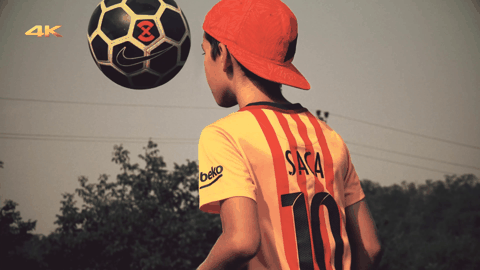

In [2]:
d = d4rt(video)
viz.video_player(video)

## 2 · Pick a point in frame 0

Choose a pixel on the ball: **`u = 0.29`, `v = 0.18`**.
Coordinates run from 0 to 1: `u` goes left to right; `v` goes top to bottom.

Ask: **“Where is this point in frame 31?”**

| Argument | Value | Meaning |
|:--|:--|:--|
| `u, v` | `0.29, 0.18` | Select the ball pixel in the source frame |
| `t_src` | `0` | Identify the point in frame 0 |
| `t_tgt` | `31` | Predict its position in frame 31 |
| `t_cam` | `31` | Express the answer in frame 31's camera coordinates |

The yellow marker shows the selected point; the teal marker shows the predicted position.

3D position (X, Y, Z): [-2.41  -0.146  5.117]
Visibility: 0.52


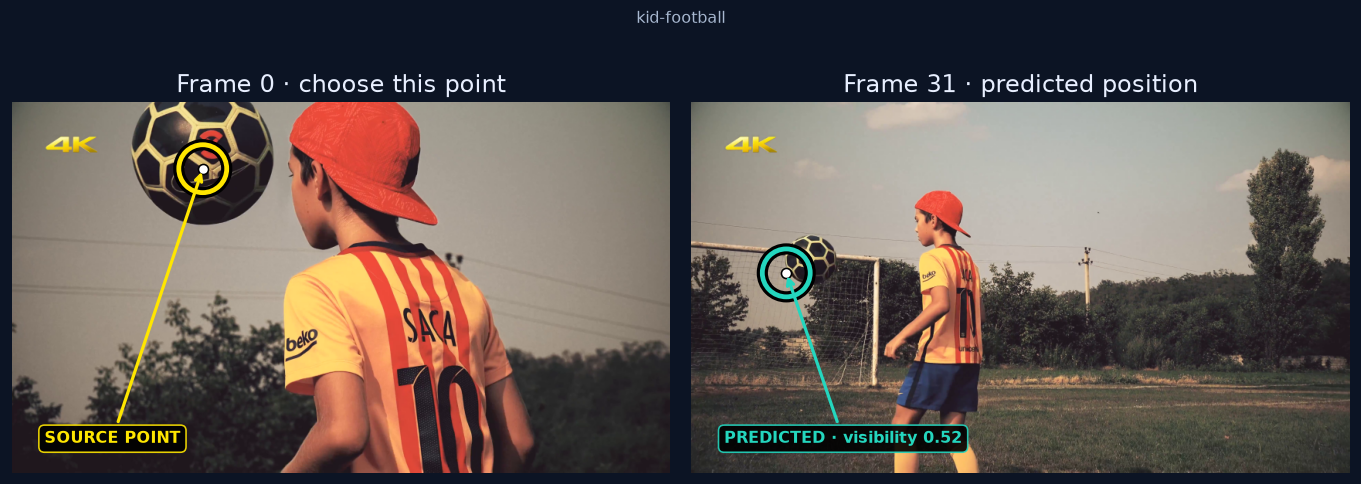

In [3]:
u, v = 0.29, 0.18

p = d.query(u, v, t_src=0, t_tgt=31, t_cam=31)

print("3D position (X, Y, Z):", np.round(p.xyz, 3))
print("Visibility:", round(float(p.visibility), 2))
viz.point_view(video, (u, v), p, source=0, target=31)

## 3 · A depth map is a grid of point queries

Ask about **many pixels in frame 0**, at time 0, in camera 0.
The **Z coordinate** of each 3D answer gives its depth.
Here we sample a 64 × 40 grid, or **2,560 pixels**.

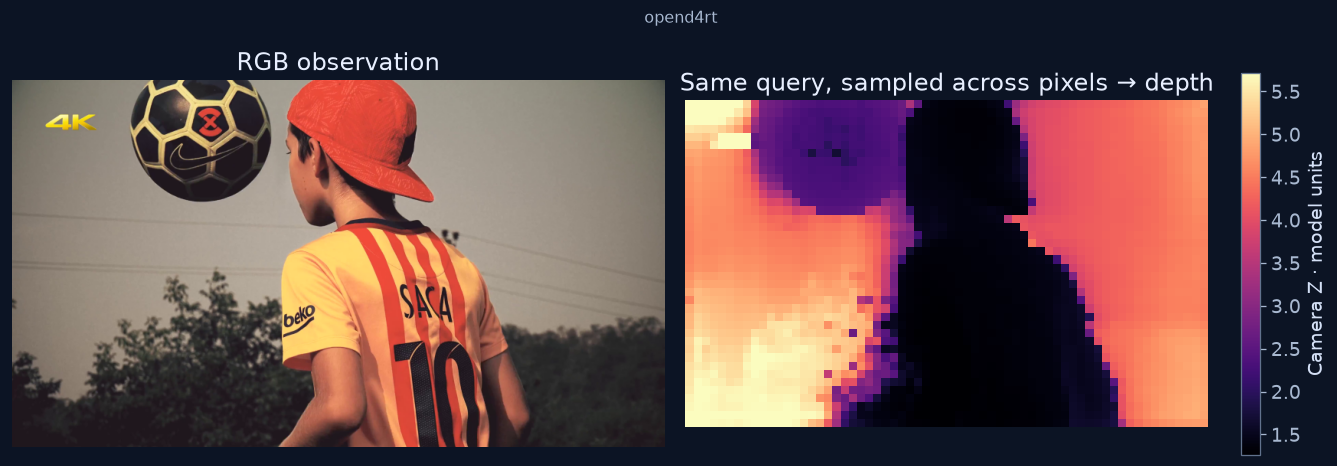

In [4]:
U, V = pixel_grid(cols=64, rows=40, margin=0)
surface = d.query(U, V, t_src=0, t_tgt=0, t_cam=0)
depth = surface.depth  # Z coordinate at each grid pixel

viz.depth_view(video, surface)

## 4 · Track the same point over time

Keep the **same `(u, v)` from frame 0**. Ask for every target frame instead of just frame 31.
We use each target frame's camera so its predicted pixel can be drawn on that image.

This returns **32 positions for one point**. Press Play or scrub the slider to follow it.
The visibility score can drop when tracking becomes difficult or the point is occluded.

32 positions × 3 coordinates: (32, 3)


<iframe title="One point tracked through time" style="width:100%;height:620px;border:0;border-radius:12px" srcdoc="<!doctype html><html><head><meta charset="utf-8"><style>
 * {box-sizing:border-box} body {margin:0;padding:16px;background:#0c1424;color:#e8efff;font:15px system-ui}
 .wrap {max-width:820px;margin:auto} canvas {width:100%;display:block;border-radius:10px;background:#111d32}
 .controls {display:flex;gap:14px;align-items:center;margin-top:14px}
 button {background:#24d6be;color:#0c1424;border:0;border-radius:6px;padding:8px 18px;font-weight:700;cursor:pointer}
 input {flex:1;min-width:80px;accent-color:#24d6be} #status {margin:12px 0;font-variant-numeric:tabular-nums}
 .hint {color:#a8b8d0;font-size:13px}
 </style></head><body><div class="wrap"><canvas id="video"></canvas>
 <div class="controls"><button id="play">Play</button><input id="frame" type="range" min="0" value="0" aria-label="Target frame"></div>
 <div id="status"></div><div class="hint">One source point from frame 0. The ring follows its predicted position; the line shows its path.</div>
 </div><script>
 const data={"frames": ["", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", "", ""], "width": 640, "height": 360, "fps": 12.0, "uv": [[0.28095000982284546, 0.19086334109306335], [0.3041468858718872, 0.3171105980873108], [0.34151649475097656, 0.44419634342193604], [0.36568957567214966, 0.6186594367027283], [0.3945040702819824, 0.7567957639694214], [0.3968299627304077, 0.8660038113594055], [0.3859482407569885, 0.9119024276733398], [0.35659676790237427, 0.9148319959640503], [0.32504647970199585, 0.8572752475738525], [0.2883140444755554, 0.7508593797683716], [0.2636846899986267, 0.6378486752510071], [0.24192436039447784, 0.5989013314247131], [0.21380072832107544, 0.6150001883506775], [0.17891308665275574, 0.718077540397644], [0.15250809490680695, 0.8219053149223328], [0.1380244344472885, 0.9337830543518066], [0.11903025209903717, 0.991016149520874], [0.09717179834842682, 0.930210292339325], [0.09048247337341309, 0.75637286901474], [0.09200020879507065, 0.6189090013504028], [0.09350653737783432, 0.5327809453010559], [0.09398667514324188, 0.4809102416038513], [0.09542971849441528, 0.4799317419528961], [0.09465616196393967, 0.5056483149528503], [0.10000591725111008, 0.55296391248703], [0.10742098093032837, 0.6472184062004089], [0.12133461236953735, 0.7160640954971313], [0.11941646039485931, 0.7587468028068542], [0.1259649246931076, 0.6750814914703369], [0.1285592019557953, 0.584741473197937], [0.1426449418067932, 0.5060411095619202], [0.14391864836215973, 0.4615907371044159]], "visibility": [0.9999816417694092, 0.679602324962616, 0.6085063815116882, 0.47292864322662354, 0.16542667150497437, 0.07679657638072968, 0.07838630676269531, 0.1630171239376068, 0.30328044295310974, 0.27706179022789, 0.25125575065612793, 0.30072709918022156, 0.3792887330055237, 0.4967086911201477, 0.5375872254371643, 0.43985894322395325, 0.2171722650527954, 0.41489121317863464, 0.5953364968299866, 0.6305500864982605, 0.655238687992096, 0.6793741583824158, 0.6544535756111145, 0.6349784731864929, 0.5668932795524597, 0.5283519625663757, 0.518290102481842, 0.510969877243042, 0.47140008211135864, 0.4652966558933258, 0.4818373918533325, 0.5226716995239258]}, canvas=document.getElementById('video'), ctx=canvas.getContext('2d');
 const slider=document.getElementById('frame'), play=document.getElementById('play'), status=document.getElementById('status');
 canvas.width=data.width;canvas.height=data.height;slider.max=data.frames.length-1;
 let t=0,timer=null;
 const images=data.frames.map(src=>{const im=new Image();im.src=src;im.onload=()=>draw();return im});
 function draw() {
 if (!images[t].complete || !images[t].naturalWidth) return;
 ctx.clearRect(0,0,canvas.width,canvas.height);ctx.drawImage(images[t],0,0,canvas.width,canvas.height);
 ctx.lineWidth=3;
 for(let i=1;i<=t;i++) {
 const a=data.uv[i-1],b=data.uv[i];if(!a||!b)continu
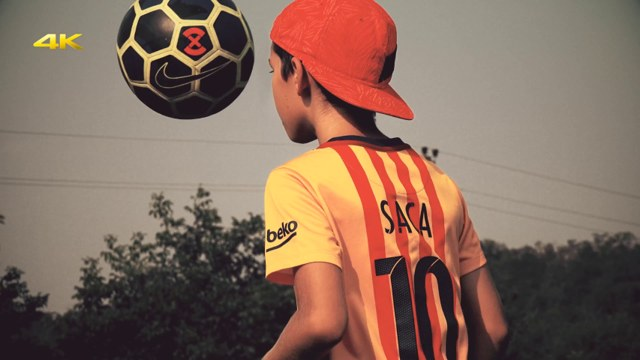
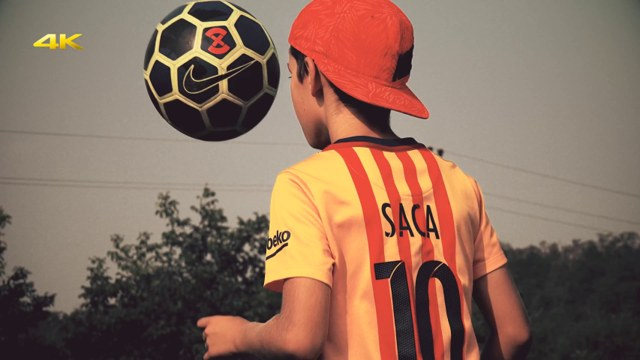
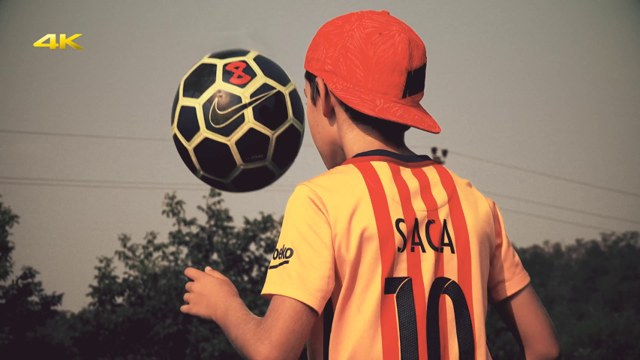
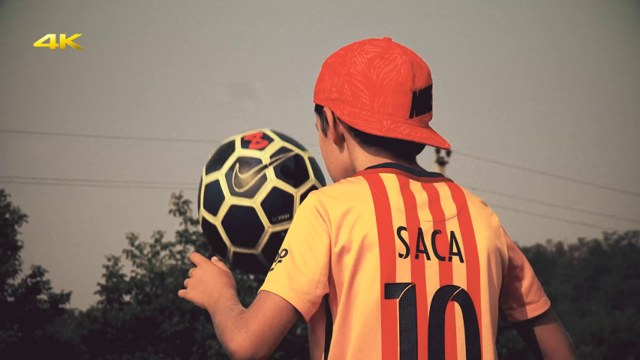
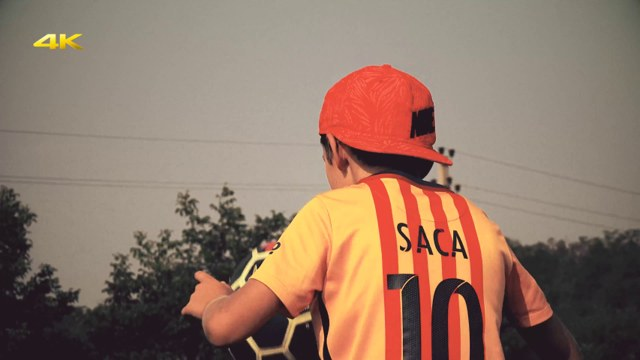
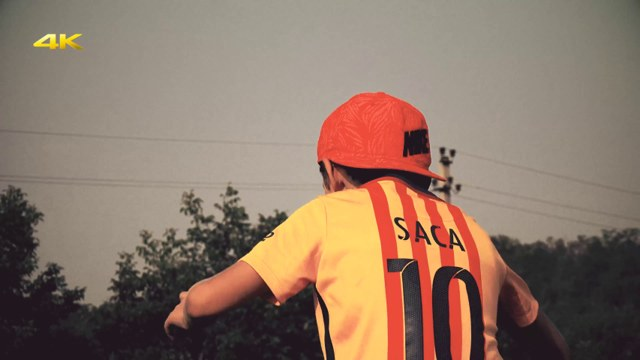
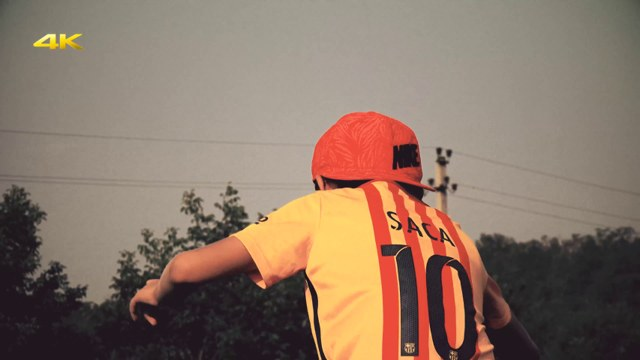
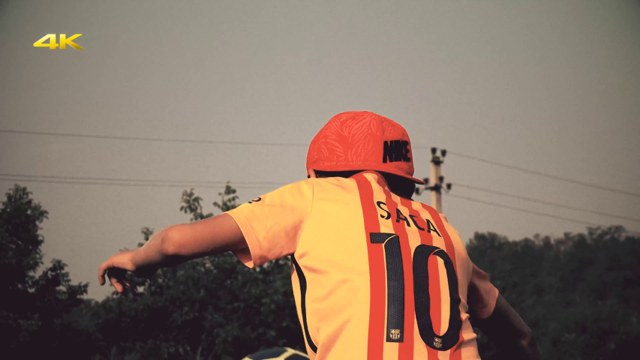
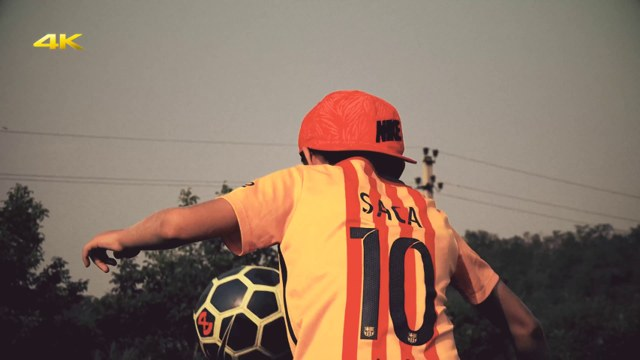
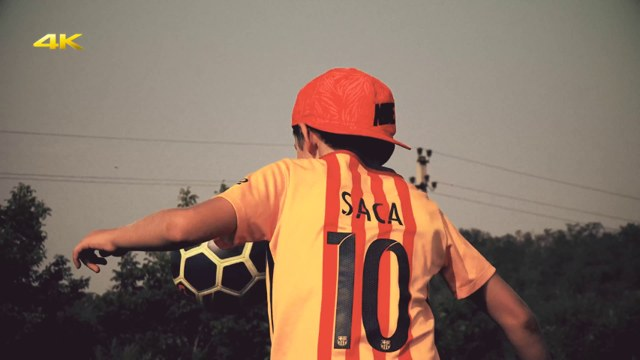
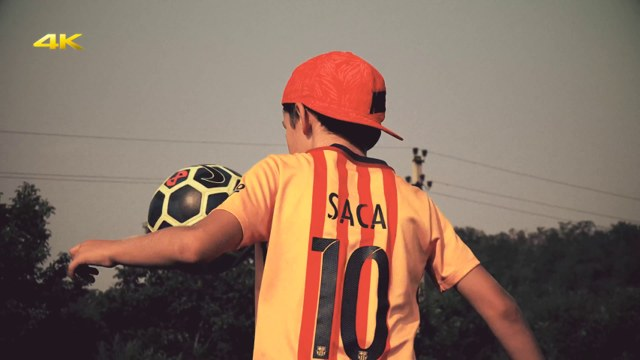
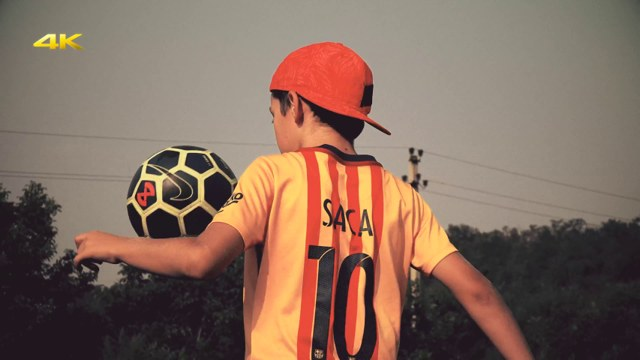
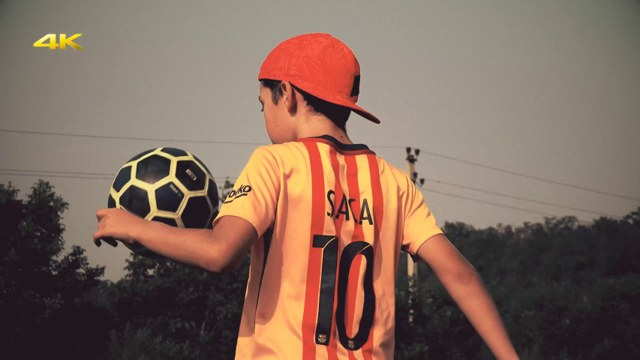
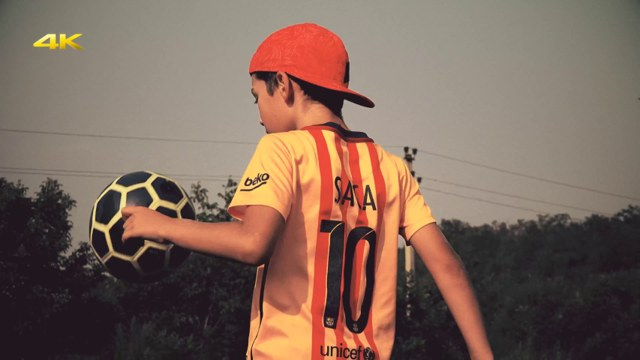
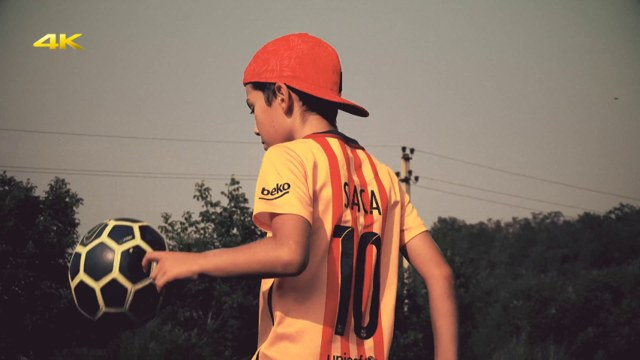
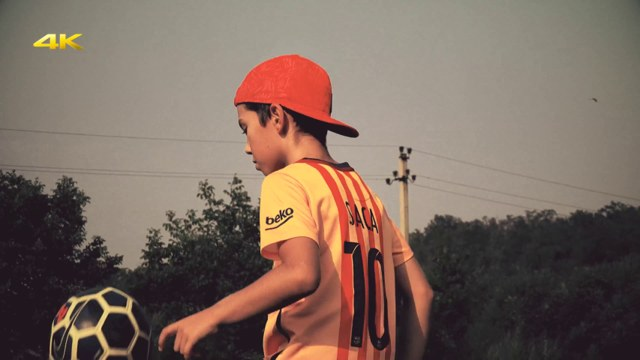
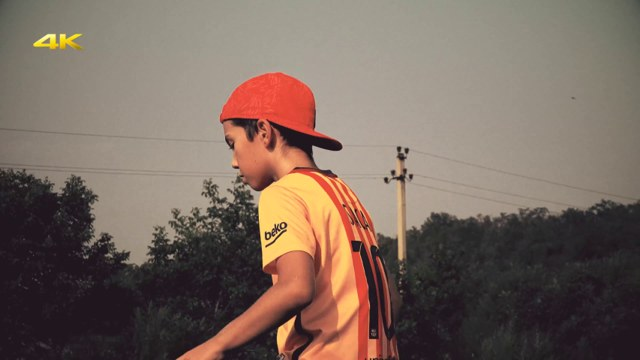
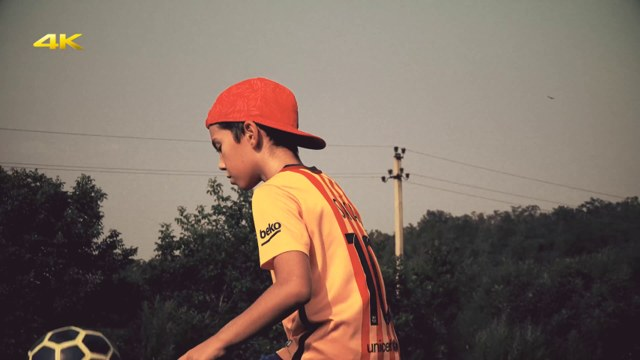
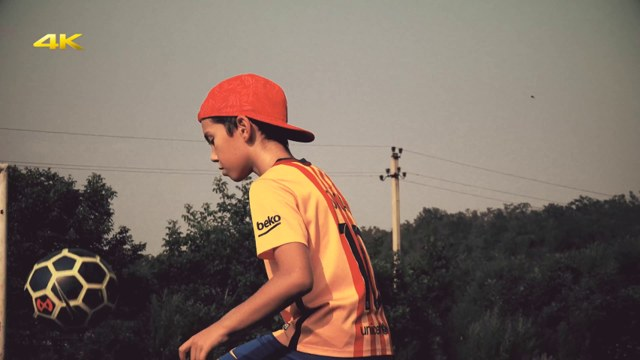
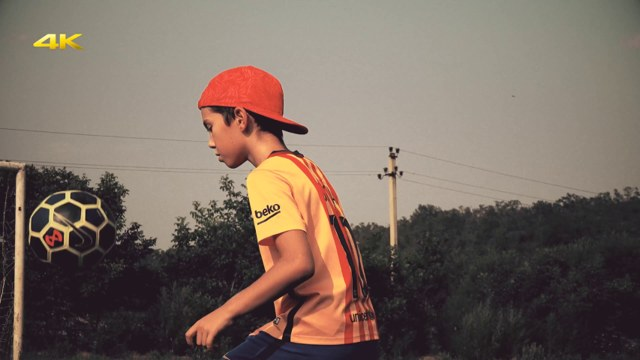
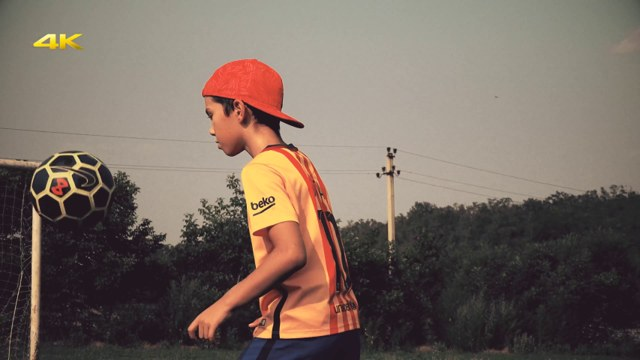
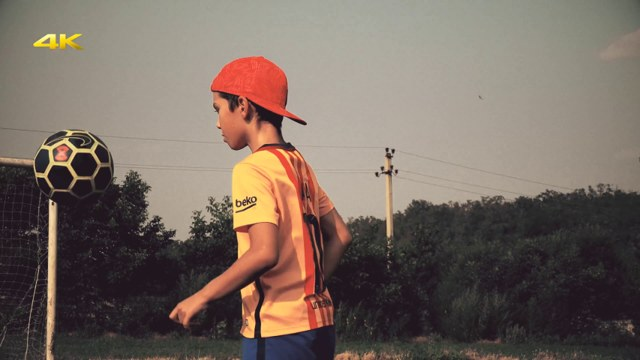
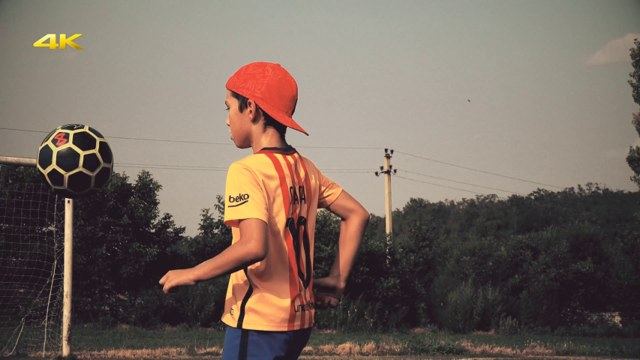
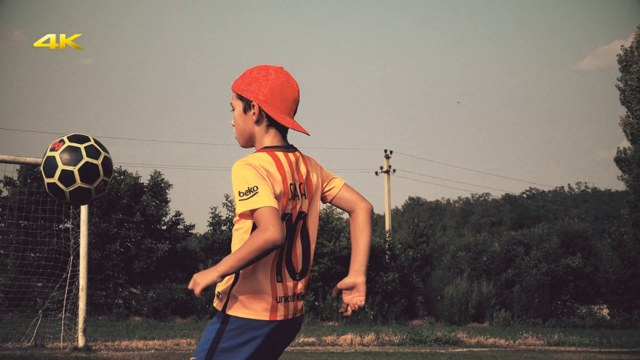
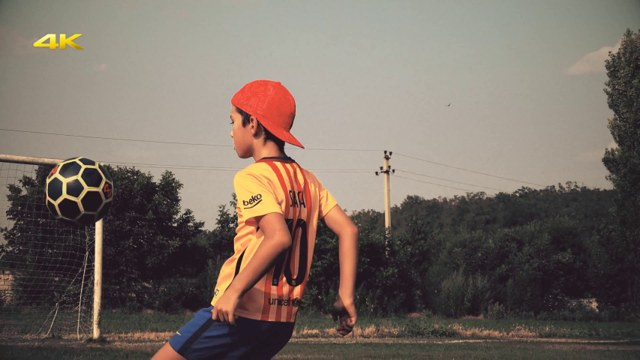
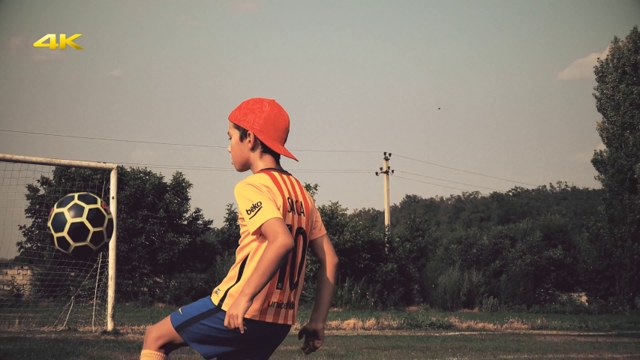
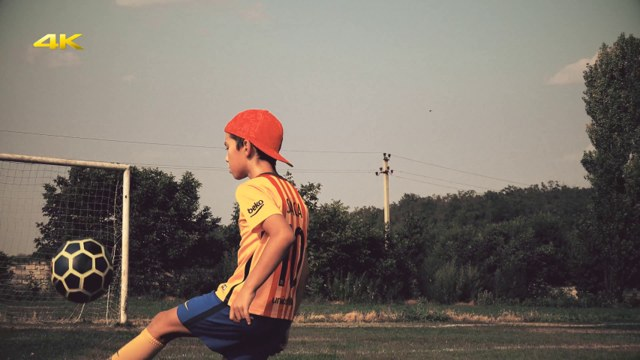
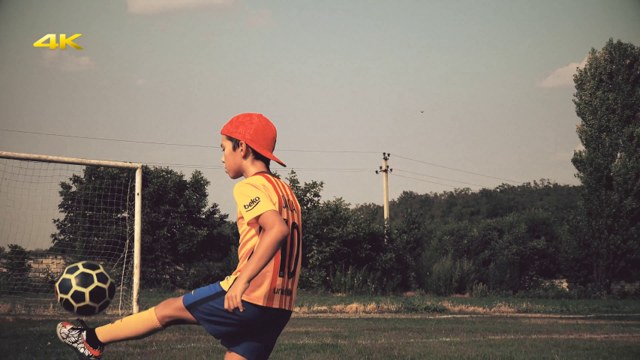
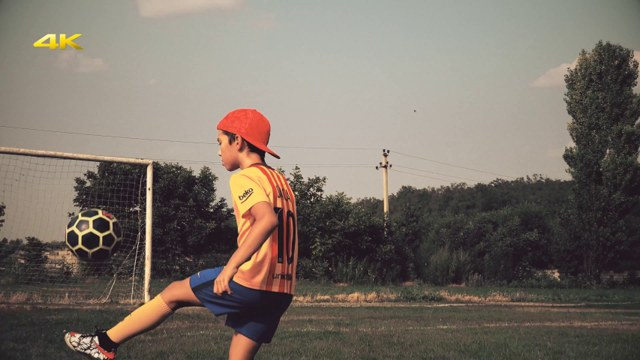
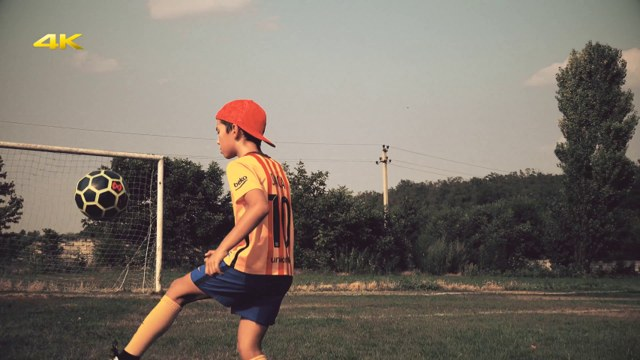
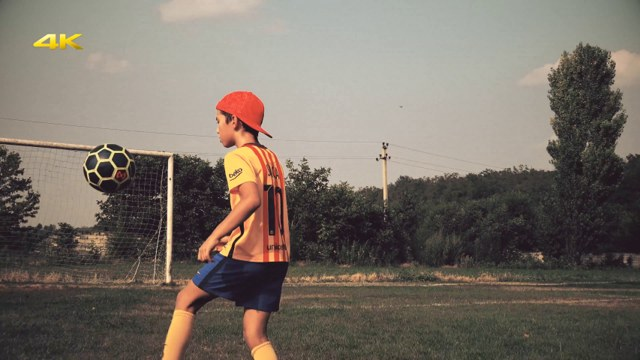
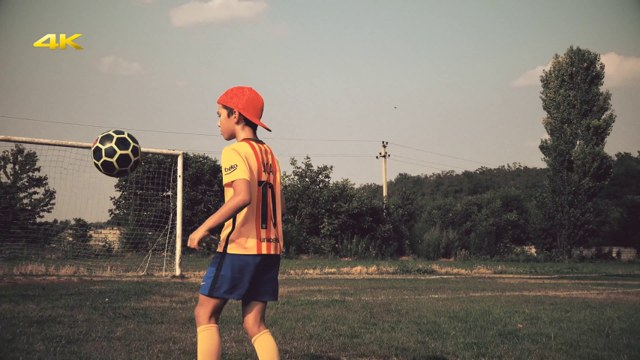

In [5]:
times = np.arange(len(video))  # 0, 1, ..., 31
track = d.query(u, v, t_src=0, t_tgt=times, t_cam=times)

print("32 positions × 3 coordinates:", track.xyz.shape)
viz.point_track_player(video, track)

*Real predictions from [OpenD4RT](https://github.com/Lijiaxin0111/Open-d4rt),
an unofficial implementation of [D4RT](https://d4rt-paper.github.io/).
Video: DAVIS `kid-football`, from [Lightricks' public mirror](https://huggingface.co/datasets/Lightricks/Canny-Control-Dataset).
Geometry is in model units; visibility is a model score.*